Neural Style Transfer

In [ ]:
print("Task 5 - Neural Style Transfer")
print("Project started successfully!")

Task 5 - Neural Style Transfer
Project started successfully!


Checking GPU

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("✅ GPU is ready!")
else:
    print("⚠️ GPU not detected. Please enable T4 GPU.")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU is ready!


Importing Libraries

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

print("All required libraries imported successfully!")

All required libraries imported successfully!


Downloading Content Images & Style Images

In [ ]:
import urllib.request

content_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg"
style_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/Vassily_Kandinsky%2C_1913_-_Composition_7.jpg"

urllib.request.urlretrieve(content_url, "content.jpg")
urllib.request.urlretrieve(style_url, "style.jpg")

print("Content image downloaded successfully!")
print("Style image downloaded successfully!")

Content image downloaded successfully!
Style image downloaded successfully!


Display Content and Size Images

Content image size: (700, 577)
Style image size: (1000, 657)


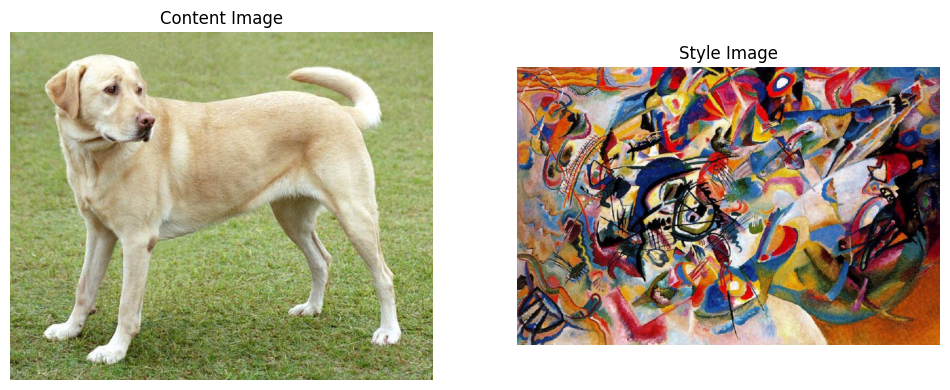

In [ ]:
content_image = Image.open("content.jpg")
style_image = Image.open("style.jpg")

print("Content image size:", content_image.size)
print("Style image size:", style_image.size)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(content_image)
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(style_image)
plt.title("Style Image")
plt.axis("off")

plt.show()

Preprocess Images for VGG19

In [ ]:
IMG_SIZE = 256

def load_and_process_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)

    # Add batch dimension
    image = image[tf.newaxis, :]

    return image

content_tensor = load_and_process_image("content.jpg")
style_tensor = load_and_process_image("style.jpg")

print("Content tensor shape:", content_tensor.shape)
print("Style tensor shape:", style_tensor.shape)
print("Images preprocessed successfully!")

Content tensor shape: (1, 256, 256, 3)
Style tensor shape: (1, 256, 256, 3)
Images preprocessed successfully!


Loading Pretrained VGG19

In [ ]:
vgg = tf.keras.applications.VGG19(
    include_top=False,
    weights="imagenet"
)

vgg.trainable = False

print("VGG19 loaded successfully!")
print("Total layers:", len(vgg.layers))
print("Model is frozen:", not vgg.trainable)

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
VGG19 loaded successfully!
Total layers: 22
Model is frozen: True


Select Content and Style Layers

In [ ]:
content_layer = "block5_conv2"

style_layers = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1"
]

print("Content layer:", content_layer)
print("Style layers:")

for layer in style_layers:
    print("-", layer)

Content layer: block5_conv2
Style layers:
- block1_conv1
- block2_conv1
- block3_conv1
- block4_conv1
- block5_conv1


Creating Feature Extracting Model

In [ ]:
selected_layers = style_layers + [content_layer]

outputs = [vgg.get_layer(layer).output for layer in selected_layers]

feature_model = tf.keras.Model(
    inputs=vgg.input,
    outputs=outputs
)

print("Feature extraction model created successfully!")
print("Number of output features:", len(outputs))

Feature extraction model created successfully!
Number of output features: 6


Preprocess Images for VGG19

In [ ]:
def preprocess_for_vgg(image):
    # Convert RGB to BGR and apply VGG19 preprocessing
    image = tf.keras.applications.vgg19.preprocess_input(image)
    return image

content_vgg = preprocess_for_vgg(content_tensor)
style_vgg = preprocess_for_vgg(style_tensor)

print("Content image prepared for VGG19:", content_vgg.shape)
print("Style image prepared for VGG19:", style_vgg.shape)
print("VGG19 preprocessing completed successfully!")

Content image prepared for VGG19: (1, 256, 256, 3)
Style image prepared for VGG19: (1, 256, 256, 3)
VGG19 preprocessing completed successfully!


Extract Content and Style Features

In [ ]:
style_outputs = feature_model(style_vgg)
content_outputs = feature_model(content_vgg)

# Style features
style_features = style_outputs[:-1]

# Content feature
content_features = content_outputs[-1]

print("Style features extracted:", len(style_features))
print("Content feature shape:", content_features.shape)

for i, feature in enumerate(style_features):
    print(f"Style feature {i+1} shape:", feature.shape)

Style features extracted: 5
Content feature shape: (1, 16, 16, 512)
Style feature 1 shape: (1, 256, 256, 64)
Style feature 2 shape: (1, 128, 128, 128)
Style feature 3 shape: (1, 64, 64, 256)
Style feature 4 shape: (1, 32, 32, 512)
Style feature 5 shape: (1, 16, 16, 512)


Calculating Gram Matrix

In [ ]:
def gram_matrix(feature):
    # Feature shape: (batch, height, width, channels)
    result = tf.linalg.einsum("bijc,bijd->bcd", feature, feature)

    input_shape = tf.shape(feature)
    num_locations = tf.cast(
        input_shape[1] * input_shape[2],
        tf.float32
    )

    return result / num_locations


style_gram_matrices = [
    gram_matrix(feature)
    for feature in style_features
]

print("Gram matrices calculated successfully!")
print("Number of Gram matrices:", len(style_gram_matrices))

for i, gram in enumerate(style_gram_matrices):
    print(f"Gram matrix {i+1} shape:", gram.shape)

Gram matrices calculated successfully!
Number of Gram matrices: 5
Gram matrix 1 shape: (1, 64, 64)
Gram matrix 2 shape: (1, 128, 128)
Gram matrix 3 shape: (1, 256, 256)
Gram matrix 4 shape: (1, 512, 512)
Gram matrix 5 shape: (1, 512, 512)


Define Style Loss and Content Loss

In [ ]:
def content_loss(content_target, content_generated):
    return tf.reduce_mean(
        tf.square(content_target - content_generated)
    )


def style_loss(style_target, style_generated):
    return tf.reduce_mean(
        tf.square(style_target - style_generated)
    )


print("Content loss function created successfully!")
print("Style loss function created successfully!")

Content loss function created successfully!
Style loss function created successfully!


Initialize the Generates Image

In [ ]:
generated_image = tf.Variable(content_tensor, dtype=tf.float32)

print("Generated image initialized successfully!")
print("Generated image shape:", generated_image.shape)

Generated image initialized successfully!
Generated image shape: (1, 256, 256, 3)


Set Style and Content Weights

In [ ]:
CONTENT_WEIGHT = 1e4
STYLE_WEIGHT = 1e-2

print("Content weight:", CONTENT_WEIGHT)
print("Style weight:", STYLE_WEIGHT)
print("Style transfer weights configured successfully!")

Content weight: 10000.0
Style weight: 0.01
Style transfer weights configured successfully!


Create Total Style Transfer Loss

In [ ]:
def total_loss_function(generated_features):
    # Generated content feature
    generated_content = generated_features[-1]

    # Content loss
    c_loss = content_loss(
        content_features,
        generated_content
    )

    # Generated style features
    generated_style_features = generated_features[:-1]

    # Calculate style loss for all style layers
    s_loss = 0.0

    for target_gram, generated_feature in zip(
        style_gram_matrices,
        generated_style_features
    ):
        generated_gram = gram_matrix(generated_feature)
        s_loss += style_loss(
            target_gram,
            generated_gram
        )

    # Average style loss
    s_loss /= len(style_gram_matrices)

    # Total weighted loss
    total_loss = (
        CONTENT_WEIGHT * c_loss +
        STYLE_WEIGHT * s_loss
    )

    return total_loss, c_loss, s_loss


print("Total loss function created successfully!")

Total loss function created successfully!


Create the Optimization Step

In [ ]:
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.02
)

@tf.function
def train_step():
    with tf.GradientTape() as tape:
        generated_vgg = preprocess_for_vgg(generated_image)
        generated_features = feature_model(generated_vgg)

        total_loss, c_loss, s_loss = total_loss_function(
            generated_features
        )

    gradients = tape.gradient(
        total_loss,
        generated_image
    )

    optimizer.apply_gradients(
        [(gradients, generated_image)]
    )

    # Keep pixel values in valid image range
    generated_image.assign(
        tf.clip_by_value(generated_image, 0.0, 255.0)
    )

    return total_loss, c_loss, s_loss


print("Optimization step created successfully!")

Optimization step created successfully!


Start Neural Style Transfer

In [ ]:
EPOCHS = 3
STEPS_PER_EPOCH = 100

print("Starting Neural Style Transfer...")
print("Epochs:", EPOCHS)
print("Steps per epoch:", STEPS_PER_EPOCH)

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    for step in range(STEPS_PER_EPOCH):
        total_loss, c_loss, s_loss = train_step()

        if (step + 1) % 25 == 0:
            print(
                f"Step {step + 1}/{STEPS_PER_EPOCH} | "
                f"Total Loss: {total_loss.numpy():.2f} | "
                f"Content Loss: {c_loss.numpy():.2f} | "
                f"Style Loss: {s_loss.numpy():.2f}"
            )

print("\nNeural Style Transfer completed successfully!")

Starting Neural Style Transfer...
Epochs: 3
Steps per epoch: 100

Epoch 1/3
Step 25/100 | Total Loss: 2224844032.00 | Content Loss: 20.88 | Style Loss: 222463524864.00
Step 50/100 | Total Loss: 2156183040.00 | Content Loss: 89.94 | Style Loss: 215528374272.00
Step 75/100 | Total Loss: 2082882560.00 | Content Loss: 207.57 | Style Loss: 208080699392.00
Step 100/100 | Total Loss: 2005917184.00 | Content Loss: 364.25 | Style Loss: 200227471360.00

Epoch 2/3
Step 25/100 | Total Loss: 1926844288.00 | Content Loss: 544.51 | Style Loss: 192139919360.00
Step 50/100 | Total Loss: 1847403136.00 | Content Loss: 734.88 | Style Loss: 184005443584.00
Step 75/100 | Total Loss: 1768759424.00 | Content Loss: 923.55 | Style Loss: 175952396288.00
Step 100/100 | Total Loss: 1691898752.00 | Content Loss: 1105.62 | Style Loss: 168084258816.00

Epoch 3/3
Step 25/100 | Total Loss: 1617578368.00 | Content Loss: 1276.71 | Style Loss: 160481132544.00
Step 50/100 | Total Loss: 1546195328.00 | Content Loss: 1434.15

Display Final Result

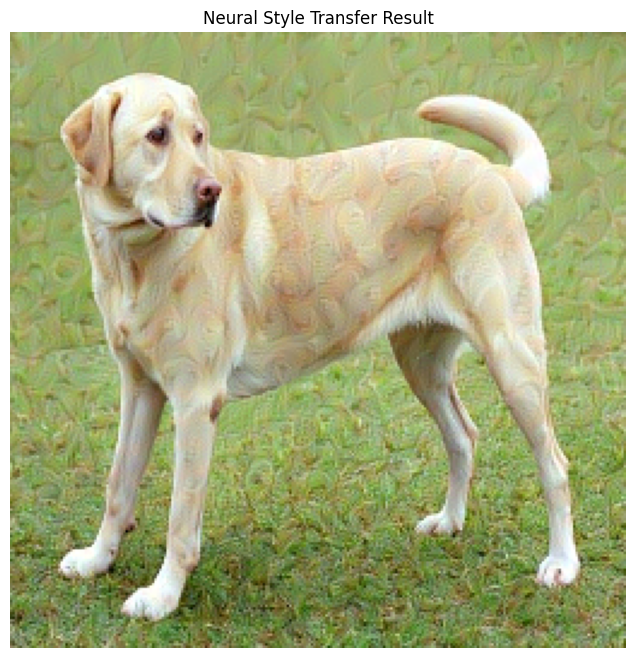

In [ ]:
plt.figure(figsize=(8, 8))
plt.imshow(tf.cast(generated_image[0], tf.uint8))
plt.axis("off")
plt.title("Neural Style Transfer Result")
plt.show()

Saving the Generated Image

In [ ]:
output_image = tf.cast(generated_image[0], tf.uint8).numpy()

Image.fromarray(output_image).save("neural_style_transfer_output.png")

print("Generated image saved successfully!")
print("File: neural_style_transfer_output.png")

Generated image saved successfully!
File: neural_style_transfer_output.png


Creating a Comparison Image

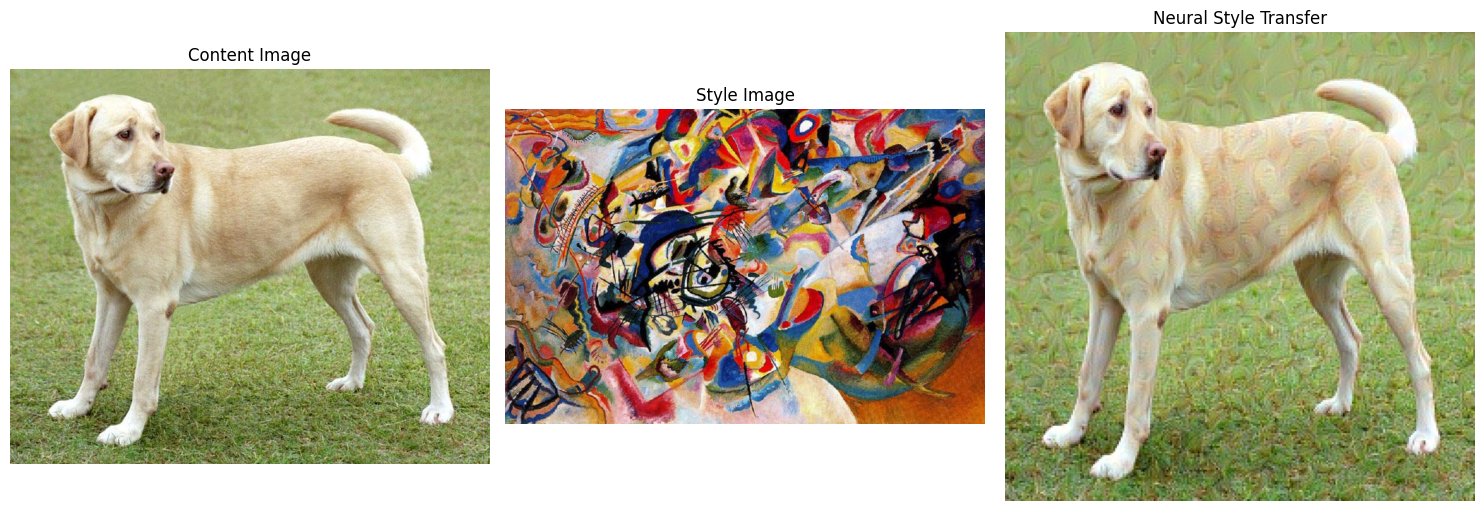

Comparison image saved successfully!
File: comparison.png


In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(Image.open("content.jpg"))
plt.title("Content Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(Image.open("style.jpg"))
plt.title("Style Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(Image.open("neural_style_transfer_output.png"))
plt.title("Neural Style Transfer")
plt.axis("off")

plt.tight_layout()
plt.savefig("comparison.png", dpi=150, bbox_inches="tight")
plt.show()

print("Comparison image saved successfully!")
print("File: comparison.png")

Creating README.md

In [ ]:
readme_content = """
# Prodigy Internship Task 5 - Neural Style Transfer

## Objective
Implement Neural Style Transfer using a pre-trained VGG19 model.

## Approach
- Used a content image and a style image.
- Used pre-trained VGG19 from TensorFlow/Keras.
- Extracted content features from `block5_conv2`.
- Extracted style features from multiple VGG19 layers.
- Calculated Gram matrices to represent image style.
- Optimized the generated image using content loss and style loss.

## Files
- `content.jpg` - Content image
- `style.jpg` - Style reference image
- `neural_style_transfer_output.png` - Final stylized image
- `comparison.png` - Content, style, and output comparison
- `PRODIGY_GA_05_Neural_Style_Transfer.ipynb` - Complete Colab notebook

## Result
The content structure is preserved while visual characteristics from the style image are transferred to the generated image.

## Technologies
- Python
- TensorFlow
- VGG19
- NumPy
- Matplotlib
- Pillow

## Task
Prodigy Infotech Generative AI Internship - Task 5
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


Final File Check

In [ ]:
import os

files = [
    "content.jpg",
    "style.jpg",
    "neural_style_transfer_output.png",
    "comparison.png",
    "README.md"
]

print("Task 5 project files:")
for file in files:
    if os.path.exists(file):
        print("✅", file)
    else:
        print("❌", file)

Task 5 project files:
✅ content.jpg
✅ style.jpg
✅ neural_style_transfer_output.png
✅ comparison.png
✅ README.md
